# 17 · Orchestrator-workers and evaluator-optimizer, as a LangGraph graph
Level L3 · Part 3 · professional · ~25 min · builds on 11

## Goal
Build the orchestrator-workers and evaluator-optimizer flow as one LangGraph graph. Fan the workers out with `Send`,
loop the draft through a judge with a conditional edge, pause for a person with `interrupt()`, then draw the graph and
step through the saved run. Your own code is only the nodes; the flow is LangGraph's.

## Why it matters
One customer message often holds two jobs: "Where is order 1093?" needs an order lookup, and "Can I get my money back
for order 2207?" needs the returns policy. One prompt that does both hides which part went wrong, and nothing checks
the reply before the customer reads it.

| Without a split and a check | With an orchestrator and an evaluator |
|---|---|
| One prompt does every job; a wrong part hides | Each subtask is a node with its own saved result |
| The first draft goes straight to the customer | An evaluator node checks the draft against criteria first |
| "Your refund is approved" goes out unchecked | The judge's edge goes to a person, who writes the reply |

**What it makes easy:** every step is saved, so you can see which node sent the draft where. **When you don't need
it:** a question with one answer and no check, or a fixed workflow (lesson 15).

## The idea
A LangGraph flow has three parts: **nodes** (functions that do one job), **edges** (what runs next) and a **state**
(a typed record that each node reads and changes). Three features do the work here:

- **`Send`** fans out: the orchestrator's edge returns one `Send` per subtask, and the workers run at the same time.
- **A conditional edge** routes after the judge: back to the writer with the problems, on to the reply, or to a person.
- **`interrupt()`** pauses the run at the handoff. The run is saved and waits until a person resumes it.

Analogy: a newsroom. An editor splits a story into research tasks, a writer drafts, and a copy editor checks the draft
against the style sheet. The routing sheet on the wall says where each draft goes next.

You have used LangGraph since lesson 02. Lesson 11 explains why a graph keeps state and pauses.

## Picture
```mermaid
flowchart LR
  S([start]) --> P[plan: orchestrator, call 1]
  P -. Send, one per subtask .-> W[worker: code, in parallel]
  W --> D[draft: writer]
  D --> J[judge: evaluator]
  J -->|pass| R[send: the reply]
  J -->|fail, rounds left| D
  J -->|fail, no rounds left| H[handoff: interrupt, a person writes it]
  R --> E([end])
  H --> E
```
Step 3 draws the real graph from the compiled app, so the picture above is checked against the code.

## Step by step

**Step 1 · setup and data (one client for the lesson).** The model comes from `llm_setup.get_llm()`, the course's shared
setup: its key is read from `.env`, never typed here. `llm_replay` is a course helper, not part of LangGraph: it saves
each model call the first time, so later runs replay the same answers. The model id is pinned, as in lessons 02 to 11.

In [1]:
import sys; sys.path.insert(0, "../../..")
import llm_replay  # course helper: records and replays model calls (not part of LangGraph)
llm_replay.start("17_orchestrator-and-evaluator")

from llm_setup import get_llm  # course helper: the shared model setup (the course model on Vertex AI, temperature 0)

llm = get_llm()  # the course's pinned model; the same setup as lessons 02 to 11 and 19

LLM mode: replay (17_orchestrator-and-evaluator.yaml)


Gemini on Vertex AI · API key loaded: True


**Step 1b · the data.** The policy is a short text written for this course; it agrees with the 30-day rule. The
orders are the fictional rows of lessons 05 and 08. The customer's message holds two jobs on purpose.

In [2]:
POLICY = """Brightside returns policy (written for this course; it agrees with the 30-day rule).
Items can be returned within 30 days of delivery, unused and in their original packaging.
Refunds are approved by a person on the support team. The support desk never promises a refund.
Damaged items: the customer sends a photo, and a person decides on a replacement or a refund."""
ORDERS = {  # the same fictional rows as lessons 05 and 08
    "1093": {"status": "in transit", "days_late": 3},
    "2207": {"status": "delivered", "days_late": 0},
}
MESSAGE = ("Where is order 1093? It should have arrived three days ago. "
           "Also, if I return the jacket from order 2207, can I get my money back?")
print(POLICY, "\n\ncustomer:", MESSAGE)

Brightside returns policy (written for this course; it agrees with the 30-day rule).
Items can be returned within 30 days of delivery, unused and in their original packaging.
Refunds are approved by a person on the support team. The support desk never promises a refund.
Damaged items: the customer sends a photo, and a person decides on a replacement or a refund. 

customer: Where is order 1093? It should have arrived three days ago. Also, if I return the jacket from order 2207, can I get my money back?


**Step 2 · the state and the schemas (no model call yet).** The state is the record every node shares. `facts` has a
reducer (`operator.add`): each worker adds its own fact, and none overwrites another. The other keys have one writer
each. The schemas `Plan` and `Verdict` are what the model must return, so the code can branch on them.

In [3]:
import operator
from typing import Annotated, Literal, TypedDict

from langgraph.checkpoint.memory import InMemorySaver  # saves each step in memory, for this notebook's run
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command, Send, interrupt
from pydantic import BaseModel


class Subtask(BaseModel):
    worker: Literal["order_status", "returns_policy"]  # the only workers that exist
    question: str
    order_id: str | None = None  # used by order_status only


class Plan(BaseModel):
    subtasks: list[Subtask]


class Verdict(BaseModel):
    verdict: Literal["pass", "fail"]
    problems: list[str]  # empty when the draft passes

The shared state, `DeskState`, is a `TypedDict`. `WorkerIn` is what `Send` hands to one worker run.

In [4]:
class DeskState(TypedDict):
    message: str
    plan: list  # the subtasks, as plain dicts
    facts: Annotated[list, operator.add]  # the reducer: every worker's fact is kept
    draft: str
    feedback: str  # the problems the judge named, sent back to the writer
    verdict: str
    problems: list
    rounds: int  # drafts written so far
    max_rounds: int  # the stop rule for this run: how many drafts before a person takes over
    reply: str  # the text that goes to the customer


class WorkerIn(TypedDict):
    subtask: dict  # what Send passes to one worker run

The constants are the caps and the criteria the judge checks. `plan_llm` and `judge_llm` wrap the same model so that
its answers must match `Plan` or `Verdict`. `lookup_order` is a code worker: a plain function, no model call.

In [5]:
MAX_SUBTASKS = 3  # the plan node refuses a longer plan: a cap on cost, as in lesson 05
MAX_ROUNDS = 2  # the default stop rule: at most two drafts, each judged; then a person (a run can set its own)
CRITERIA = ("1. Answers every question in the customer message. 2. Uses only the facts given; adds none. "
            "3. Promises no refund: a person approves refunds. 4. Four sentences at most.")
plan_llm = llm.with_structured_output(Plan)  # the orchestrator's answer must match Plan
judge_llm = llm.with_structured_output(Verdict)  # the evaluator's answer must match Verdict


def lookup_order(order_id: str) -> dict:
    """Code worker: a plain function, no model call."""
    return ORDERS.get(order_id, {"error": f"no order with id {order_id}"})

`plan` is the orchestrator: call 1 splits the message into subtasks. `fan_out` is the conditional edge after it: one
`Send` per subtask, so the workers run at the same time.

In [6]:
def plan(state: DeskState) -> dict:
    prompt = ("You are the orchestrator of the Brightside support desk. Split the customer message into subtasks, "
              "one question each. Use worker 'order_status' for one order (give its order_id) and 'returns_policy' "
              "for a return, refund or delivery question. Do not answer the questions yourself.\n\n"
              f"Customer message: {state['message']}")
    result = plan_llm.invoke(prompt)  # call 1
    if len(result.subtasks) > MAX_SUBTASKS:
        raise ValueError(f"the plan has {len(result.subtasks)} subtasks; the cap is {MAX_SUBTASKS}")
    return {"plan": [s.model_dump() for s in result.subtasks]}


def fan_out(state: DeskState) -> list[Send]:
    """The conditional edge out of plan: one Send per subtask, so the workers run at the same time."""
    return [Send("worker", {"subtask": s}) for s in state["plan"]]

`worker` runs once per `Send`. `draft` is the writer (calls 2 and 4), and `judge` is the evaluator (calls 3 and 5).
The evaluator checks one draft against the criteria and never writes the reply.

In [7]:
def worker(inp: WorkerIn) -> dict:
    sub = inp["subtask"]
    fact = lookup_order(sub["order_id"]) if sub["worker"] == "order_status" else {"policy": POLICY}
    return {"facts": [{"worker": sub["worker"], "result": fact}]}


def draft(state: DeskState) -> dict:
    prompt = ("Write the reply to the customer. Be warm and reassuring.\n"
              f"Customer message: {state['message']}\nFacts from the workers: {state['facts']}\n")
    if state["feedback"]:
        prompt += f"A reviewer found these problems in the last draft. Fix them: {state['feedback']}\n"
    return {"draft": llm.invoke(prompt).text, "rounds": state["rounds"] + 1}  # call 2 or 4


def judge(state: DeskState) -> dict:
    """The evaluator: checks one draft against the criteria. It never writes the reply."""
    prompt = (f"Check the draft against these criteria: {CRITERIA}\nFacts: {state['facts']}\n"
              f"Draft: {state['draft']}\nGive verdict pass or fail, and list the problems (empty when it passes).")
    result = judge_llm.invoke(prompt)  # call 3 or 5
    return {"verdict": result.verdict, "problems": result.problems, "feedback": "; ".join(result.problems)}

The last three nodes: `route_after_judge` is the conditional edge that sends the draft back, on, or to a person.
`send` puts the reply on the state. `handoff` pauses the run with `interrupt()`, so a person can write the reply.

In [8]:
def route_after_judge(state: DeskState) -> Literal["send", "draft", "handoff"]:
    if state["verdict"] == "pass":
        return "send"
    return "draft" if state["rounds"] < state["max_rounds"] else "handoff"


def send(state: DeskState) -> dict:
    return {"reply": state["draft"]}


def handoff(state: DeskState) -> dict:
    """Pauses the run. A person sees the draft and the problems, and resumes the run with the reply they write."""
    text = interrupt({"question": "The draft failed the checks. Write the reply yourself.",
                      "draft": state["draft"], "problems": state["problems"]})
    return {"reply": text}

**Step 3 · compile the graph and draw it (no model call).** `build_graph` wires the nodes and edges defined above. Each
`add_conditional_edges` names the routes it can return, so the drawing shows every path. The checkpointer is what makes
the handoff a saved pause. `show_graph` is a course helper that draws the compiled graph: blue nodes run code, amber nodes
call the model. The picture needs internet access; without it, the cell prints the same graph as text.

In [9]:
from IPython.display import Image, display
from langchain_core.runnables.graph import NodeStyles
from langchain_core.runnables.graph_mermaid import draw_mermaid_png

MODEL_STYLE = "classDef model fill:#fde68a,stroke:#b45309"  # amber: a node that calls the model


def show_graph(app, model_nodes=()):
    """Draw the compiled graph as a picture: blue nodes run code, amber nodes call the model.
    The picture comes from the public Mermaid service (mermaid.ink), so it needs internet access."""
    text = app.get_graph().draw_mermaid(node_colors=NodeStyles(
        default="fill:#e0f2fe,stroke:#0369a1", first="fill:#f1f5f9", last="fill:#dcfce7"))
    text += f"\n{MODEL_STYLE}\n" + (f"class {','.join(model_nodes)} model\n" if model_nodes else "")
    try:
        display(Image(draw_mermaid_png(text)))
    except Exception as e:  # offline, or the service is down: the same diagram as text
        print(f"No picture ({type(e).__name__}). The same graph as Mermaid text:\n{text}")

`build_graph` adds the six nodes, then the edges: the `Send` fan-out after `plan`, the wait for every worker before
`draft`, and the three routes after `judge`.

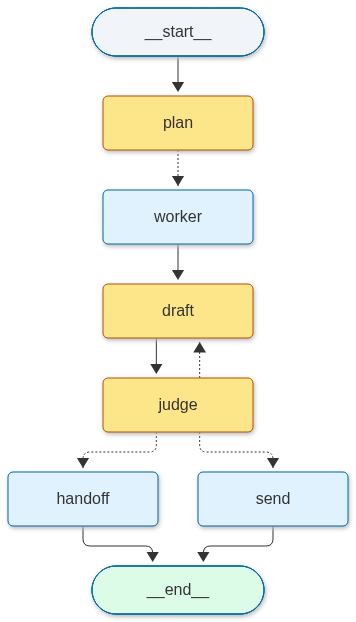

In [10]:
def build_graph():
    g = StateGraph(DeskState)
    for name, fn in [("plan", plan), ("worker", worker), ("draft", draft), ("judge", judge),
                     ("send", send), ("handoff", handoff)]:
        g.add_node(name, fn)
    g.add_edge(START, "plan")
    g.add_conditional_edges("plan", fan_out, ["worker"])  # the Send fan-out
    g.add_edge("worker", "draft")  # draft waits until every worker has finished
    g.add_edge("draft", "judge")
    g.add_conditional_edges("judge", route_after_judge, {"send": "send", "draft": "draft", "handoff": "handoff"})
    g.add_edge("send", END).add_edge("handoff", END)
    return g.compile(checkpointer=InMemorySaver())


app = build_graph()
show_graph(app, model_nodes=("plan", "draft", "judge"))  # the real graph, drawn from the compiled app

**Step 4 · run the graph and watch each node finish (5 model calls).** `stream_mode="updates"` yields one event per node
as it finishes. Each run has a thread id, and the checkpointer saves every step under it. Here the first draft fails the
judge, the second draft promises a refund and fails too, and with two rounds used up the run pauses at `handoff`.
`llm_replay.calls()` (a course helper) counts the recorded model calls.

In [11]:
KEYS = {"plan": ["plan"], "worker": ["facts"], "draft": ["rounds", "draft"], "judge": ["verdict", "problems"],
        "send": ["reply"], "handoff": ["reply"]}


def run_and_watch(message: str, thread: str, max_rounds: int = MAX_ROUNDS):
    cfg = {"configurable": {"thread_id": thread}}  # one thread id = one saved run
    inputs = {"message": message, "plan": [], "facts": [], "draft": "", "feedback": "", "verdict": "",
              "problems": [], "rounds": 0, "max_rounds": max_rounds, "reply": ""}
    for event in app.stream(inputs, cfg, stream_mode="updates"):
        for node, change in event.items():
            if node == "__interrupt__":
                print("paused:", change[0].value["question"])
                continue
            print(f"{node:<8}", {k: change[k] for k in KEYS[node] if k in change})
    return cfg


CFG = run_and_watch(MESSAGE, "desk-1093-2207")
print("\nreply:", app.get_state(CFG).values.get("reply") or "(none)")
print(f"model calls recorded so far: {llm_replay.calls()}")

plan     {'plan': [{'worker': 'order_status', 'question': 'Where is order 1093? It should have arrived three days ago.', 'order_id': '1093'}, {'worker': 'returns_policy', 'question': 'If I return the jacket from order 2207, can I get my money back?', 'order_id': '2207'}]}
worker   {'facts': [{'worker': 'order_status', 'result': {'status': 'in transit', 'days_late': 3}}]}
worker   {'facts': [{'worker': 'returns_policy', 'result': {'policy': 'Brightside returns policy (written for this course; it agrees with the 30-day rule).\nItems can be returned within 30 days of delivery, unused and in their original packaging.\nRefunds are approved by a person on the support team. The support desk never promises a refund.\nDamaged items: the customer sends a photo, and a person decides on a replacement or a refund.'}}]}
draft    {'rounds': 1, 'draft': "Subject: Update regarding your orders\n\nHi there,\n\nThank you for reaching out to us. I am so sorry to hear that your order #1093 hasn't arrived ye

**Step 5 · step through the saved run (no model call).** `get_state_history` returns every checkpoint the run saved,
newest first. Each one holds the state after a node. The printed lines show all of them, and the slider lets you move
through them one at a time.

In [12]:
import ipywidgets as widgets

history = list(reversed(list(app.get_state_history(CFG))))  # oldest first


def show_step(i: int) -> None:
    snap = history[i]
    # the nodes that ran to reach this checkpoint are the ones the previous checkpoint was waiting for
    ran = [n for n in history[i - 1].next if not n.startswith("__")] if i else []
    v = snap.values
    print(f"checkpoint {i} · after {', '.join(ran) or 'the input'} · next: {', '.join(snap.next) or 'done'}")
    print(f"    rounds {v.get('rounds', 0)} · verdict {v.get('verdict') or '-'} · "
          f"facts {len(v.get('facts', []))} · reply {'yes' if v.get('reply') else 'no'}")


for i in range(len(history)):
    show_step(i)

widgets.interact(show_step, i=widgets.IntSlider(min=0, max=len(history) - 1, value=len(history) - 1,
                                                description="checkpoint"))

checkpoint 0 · after the input · next: __start__
    rounds 0 · verdict - · facts 0 · reply no
checkpoint 1 · after the input · next: plan
    rounds 0 · verdict - · facts 0 · reply no
checkpoint 2 · after plan · next: worker, worker
    rounds 0 · verdict - · facts 0 · reply no
checkpoint 3 · after worker, worker · next: draft
    rounds 0 · verdict - · facts 2 · reply no
checkpoint 4 · after draft · next: judge
    rounds 1 · verdict - · facts 2 · reply no
checkpoint 5 · after judge · next: draft
    rounds 1 · verdict fail · facts 2 · reply no
checkpoint 6 · after draft · next: judge
    rounds 2 · verdict fail · facts 2 · reply no
checkpoint 7 · after judge · next: handoff
    rounds 2 · verdict fail · facts 2 · reply no


interactive(children=(IntSlider(value=7, description='checkpoint', max=7), Output()), _dom_classes=('widget-in…

<function __main__.show_step(i: int) -> None>

**Step 6 · the handoff: a person resumes the paused run (no model call).** The second draft failed on the last round,
so the run stopped at `handoff` and nothing went to the customer. A person reads the draft and the problems, writes the
reply, and resumes the same thread with `Command(resume=...)`. This step makes no model call, and it closes the recording.

In [13]:
state = app.get_state(CFG)
print("waiting at:", state.next, "· reply so far:", state.values.get("reply") or "(none)")

app.invoke(Command(resume="Thanks for your patience. A member of our team will review your jacket and reply today."), CFG)
print("after the person's reply:", app.get_state(CFG).values["reply"])
print(f"model calls recorded: {llm_replay.calls()}")
llm_replay.stop()  # saves the recording and closes the replay: the last cell of this notebook

waiting at: ('handoff',) · reply so far: (none)
after the person's reply: Thanks for your patience. A member of our team will review your jacket and reply today.
model calls recorded: 5


## At work
- Anthropic's essay "Building effective agents" (2024-12-19) describes orchestrator-workers for tasks whose subtasks
  you cannot predict, and evaluator-optimizer when there are clear evaluation criteria. The plan is model output, so
  teams cap and log it → lesson 36 (cost and latency).
- Parallel workers merge their results through a reducer, so none overwrites another → lesson 11 (state and graphs).
- A judge is a model too, and it can pass a bad draft. Teams measure it against labelled examples before they trust it
  → lesson 07 (eval basics), and run those checks on every change → lesson 32 (evals in CI).
- A saved pause is how production handles a person's decision: the run waits in a store, not in a thread → lesson 13
  (approval gate) and lesson 35 (durable runs).

## What just happened
- The plan split the message into two subtasks, and the two workers added two facts to `facts`.
- Draft 1 failed the judge with two problems, and draft 2 failed with one. Two rounds was the limit, so the run went to `handoff`.
- The reply stayed empty (`(none)`) until the person resumed the run. Nothing was sent to the customer.
- The notebook made 5 model calls in total (plan, two drafts, two judge checks), and the resume made none.

## Common mistakes
1. **Two parallel workers writing one key with no reducer.** LangGraph does not know how to merge them, so the run stops
   with an error. The cell below shows it with a tiny graph and no model call.

In [14]:
try:
    from typing import TypedDict as _TD


    class _Plain(_TD):
        facts: list  # no reducer: two workers in one step both write it


    _g = StateGraph(_Plain)
    _g.add_node("a", lambda s: {"facts": ["a"]}).add_node("b", lambda s: {"facts": ["b"]})
    _g.add_edge(START, "a").add_edge(START, "b").add_edge("a", END).add_edge("b", END)
    _g.compile().invoke({"facts": []})  # raises InvalidUpdateError: both nodes wrote "facts" in one step
except Exception as error:  # print the message only: a traceback shows file paths on this machine
    print(type(error).__name__, "-", str(error).splitlines()[0])

InvalidUpdateError - At key 'facts': Can receive only one value per step. Use an Annotated key to handle multiple values.


The fix is the reducer, as in `DeskState`: `facts: Annotated[list, operator.add]`.

2. **A loop with no stop rule.** A graph whose conditional edge always points back to the writer runs until LangGraph's
   `recursion_limit` stops it, and the error comes after many paid calls. Always route to an end node when the rounds
   run out, as `route_after_judge` does. The cell below shows the error with a loop that never ends. It has no model call.

In [15]:
try:
    class _Counter(_TD):
        n: int


    _loop = StateGraph(_Counter)
    _loop.add_node("step", lambda s: {"n": s["n"] + 1})
    _loop.add_edge(START, "step").add_edge("step", "step")  # always back to step: no exit
    _loop.compile().invoke({"n": 0}, {"recursion_limit": 6})  # raises GraphRecursionError at the sixth step
except Exception as error:  # print the message only: a traceback shows file paths on this machine
    print(type(error).__name__, "-", str(error).splitlines()[0])

GraphRecursionError - Recursion limit of 6 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.


## Try it
Write `route_after_judge_for(verdict, rounds, max_rounds)`. It returns `"send"` when the draft passed, `"draft"` when it
failed and rounds are left, and `"handoff"` when it failed on the last round. It is the same rule as `route_after_judge`,
with the limit passed in, so you can test it on its own. No model call is needed.

In [16]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [17]:
def route_after_judge_for(verdict: str, rounds: int, max_rounds: int) -> str:
    if verdict == "pass":
        return "send"
    return "draft" if rounds < max_rounds else "handoff"


print(route_after_judge_for("pass", 1, 2))  # send
print(route_after_judge_for("fail", 1, 2))  # draft
print(route_after_judge_for("fail", 2, 2))  # handoff

send
draft
handoff


## Key terms
- **Node** — a function that does one job and returns the part of the state it changed.
- **Edge** — the link that says what runs next; a conditional edge picks the next node from the state.
- **State** — the typed record that every node reads and changes.
- **Reducer** — the rule that merges several writes to one key, here `operator.add` for `facts`.
- **Send** — starts one worker run per subtask; the workers run in parallel.
- **Orchestrator-workers** — one model call splits the job, and workers do the parts.
- **Evaluator-optimizer** — a judge checks each draft against criteria, and the writer revises on the problems.
- **Interrupt** — pauses a run at a node and saves it until a person resumes it with `Command(resume=...)`.
- **Checkpoint** — a saved snapshot of the state after a step, kept under a thread id.
- **Recursion limit** — LangGraph's cap on steps in one run; it stops a loop that has no exit.

## Recap
- The flow is a graph: nodes do the jobs, edges say what runs next, and the state is the shared record.
- `Send` fans out the workers, and a reducer merges their results. The draft waits for all of them.
- A conditional edge sends the draft back, on to the reply, or to a person. The round limit is the stop rule.
- `interrupt()` pauses and saves the run. `Command(resume=...)` continues the same thread with a person's decision.

**Interview:** "When would you add an evaluator to a support agent?" Strong answer: "When the draft has clear criteria it
can fail, such as a promise the desk may not make. The judge is its own node with a round limit, and a draft that never
passes pauses for a person. I measure the judge against labelled examples before I trust it."